In [1]:
import pandas
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
import numpy as np
import multiprocessing as mp
from tqdm.auto import tqdm
import autograd.numpy as anp
from pathlib import Path
import sys
cwd = Path.cwd().resolve()
repo_root = cwd if (cwd / "badmet").is_dir() else cwd.parent
paper_dir = repo_root / "Paper"
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from badmet import MassEstimator, log_tau0_to_log_tau1, log_tau0_to_log_tau1_derivative
import corner
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
plt.rcParams['savefig.dpi'] = 720


# MOCK (Section 3.1)

In [2]:
mock_size = 1000
rng = np.random.default_rng(42)
LOGMBH_TRUE = rng.uniform(5, 9, size=mock_size)

def func_M_log_sigma2_NXV(log_sigma2_NXV):
    return -0.94*(log_sigma2_NXV-anp.log10(0.005))+7.41

def sigma2_NXV_from_LOGMBH(LOGMBH_TRUE):
    a = 0.94
    b = 7.41
    sigma2_NXV = 0.005 * 10**((b - rng.normal(LOGMBH_TRUE, 0.7)) / a)
    return sigma2_NXV

log_sigma2_NXV_EST_mock = rng.normal(np.log10(sigma2_NXV_from_LOGMBH(LOGMBH_TRUE)), 0.02)

def func_LOGLX(log_M_BH):
    return 0.89*(log_M_BH-8) -0.16 + 44
def MOCK_LOGLX(log_M_BH):
    return 0.89*(log_M_BH-8) -0.16 + 44

LOGLX_EST_mock = rng.normal(rng.normal(MOCK_LOGLX(LOGMBH_TRUE), 0.7), 0.2)

def func_LOGTAU(log_M_BH, z):
    return 1.28*log_M_BH-4.37+anp.log10(1+z)
def MOCK_LOGTAU(log_M_BH, z, baseline, ncadence):
    return log_tau0_to_log_tau1(1.28*log_M_BH-4.37+anp.log10(1+z), baseline, ncadence)

baseline_mock = rng.uniform(1e4, 14e4, size=mock_size)
ncadence_mock = rng.integers(50, 1401, size=mock_size)
z_mock = rng.uniform(0,0.3, size=mock_size)
LOGTAU_EST_mock = rng.normal(rng.normal(*MOCK_LOGTAU(LOGMBH_TRUE, z_mock, baseline_mock, ncadence_mock)),0.4)

In [3]:
mock_path = paper_dir / "data" / f"df_mock_{mock_size}.pkl"
df_mock = pandas.DataFrame({
    "LOGMBH_TRUE": LOGMBH_TRUE,
    "log_sigma2_NXV_EST": log_sigma2_NXV_EST_mock,
    "baseline": baseline_mock,
    "ncadence": ncadence_mock,
    "z": z_mock,
    "LOGLX_EST": LOGLX_EST_mock,
    "LOGTAU_EST": LOGTAU_EST_mock,
})
df_mock

,LOGMBH_TRUE,log_sigma2_NXV_EST,baseline,ncadence,z,LOGLX_EST,LOGTAU_EST
0,8.095824,-2.479706,131856.841805,1199,0.259155,43.239270,4.116499
1,6.755514,-2.301729,47761.143476,520,0.154110,44.030776,4.076407
2,8.434392,-3.400652,63589.984459,96,0.076246,43.996932,5.171446
3,7.789472,-2.498848,108652.351234,1035,0.207893,44.059527,4.776751
4,5.376709,-0.065017,54676.750987,973,0.130440,41.511840,2.447353
...,...,...,...,...,...,...,...
995,6.751958,-1.393168,20827.598650,397,0.237195,43.142047,3.505177
996,7.556055,-2.295291,22449.040742,813,0.166338,43.028685,3.301151
997,5.009235,0.800426,114049.014093,54,0.113218,40.880668,2.932448
998,8.973474,-4.357539,73909.246611,91,0.043716,44.168654,3.900822


In [4]:
COMBINATIONS = [
    (True,  False, False),  # 0: tau
    (False, True,  False),  # 1: Lx
    (False, False, True),   # 2: NXV
    (True,  True,  False),  # 3: tau + Lx
    (True,  False, True),   # 4: tau + NXV
    (False, True,  True),   # 5: Lx + NXV
    (True,  True,  True),   # 6: tau + Lx + NXV
]

def estimate_one_mock(index, par):

    result = {}
    
    for j, (use_tau, use_lx, use_nxv) in enumerate(COMBINATIONS):
        estimator = MassEstimator()

        if use_tau:
            estimator.add_tau(
                par["LOGTAU_EST"],
                par["baseline"],
                par["ncadence"],
                func_LOGTAU,
                0.40,
                args=[par["z"]],
                args_err=[0],
            )

        if use_lx:
            estimator.add_param(
                par["LOGLX_EST"],
                0.20,
                func_LOGLX,
                0.70,
            )

        if use_nxv:
            estimator.add_Mparam(
                func_M_log_sigma2_NXV,
                0.70,
                args=[par["log_sigma2_NXV_EST"]],
                args_err=[0.02],
            )

        samples = estimator.estimate(
            pool_size=1,
            progress=False,
        )

        q16, median, q84 = np.percentile(
            samples,
            [16, 50, 84],
        )

        result[f"LOGMBH_{j}"] = median
        result[f"LOGMBH_{j}_ERR_HI"] = q84 - median
        result[f"LOGMBH_{j}_ERR_LO"] = median - q16

    return index, result

def estimate_one_mock_task(task):
    return estimate_one_mock(*task)

In [5]:
# %%time
    
# tasks = [
#     (int(index), row.to_dict())
#     for index, row in df_mock.iterrows()
# ]

# with mp.Pool(processes=12) as pool:
#     result_pairs = list(
#         tqdm(
#             pool.imap_unordered(
#                 estimate_one_mock_task,
#                 tasks,
#                 chunksize=1,
#             ),
#             total=len(tasks),
#             desc="Estimating mock masses",
#         )
#     )

# result_df = pandas.DataFrame.from_dict(
#     dict(result_pairs),
#     orient="index",
# ).reindex(df_mock.index)

# df_mock[result_df.columns] = result_df
# df_mock.to_pickle(mock_path)

# df_mock

In [6]:
df_mock = pandas.read_pickle(mock_path)
assert len(df_mock) == mock_size
df_mock

,LOGMBH_TRUE,log_sigma2_NXV_EST,baseline,ncadence,z,LOGLX_EST,LOGTAU_EST,LOGMBH_0,LOGMBH_0_ERR_HI,LOGMBH_0_ERR_LO,...,LOGMBH_3_ERR_LO,LOGMBH_4,LOGMBH_4_ERR_HI,LOGMBH_4_ERR_LO,LOGMBH_5,LOGMBH_5_ERR_HI,LOGMBH_5_ERR_LO,LOGMBH_6,LOGMBH_6_ERR_HI,LOGMBH_6_ERR_LO
0,8.095824,-2.479706,131856.841805,1199,0.259155,43.239270,4.116499,8.424243,2.384638,1.708269,...,0.548954,7.392308,0.746270,0.597937,7.480975,0.508477,0.530331,7.362386,0.552800,0.477085
1,6.755514,-2.301729,47761.143476,520,0.154110,44.030776,4.076407,9.089080,1.942777,2.003961,...,0.795298,7.424385,0.698789,0.592976,7.703038,0.552346,0.484998,7.767781,0.491326,0.505087
2,8.434392,-3.400652,63589.984459,96,0.076246,43.996932,5.171446,9.518979,1.647659,1.693225,...,0.659324,8.459302,0.659086,0.630704,8.339847,0.526371,0.517521,8.356642,0.498821,0.497415
3,7.789472,-2.498848,108652.351234,1035,0.207893,44.059527,4.776751,9.609136,1.670461,1.797785,...,0.716366,7.719694,0.590322,0.515316,7.876472,0.500465,0.461649,7.965053,0.493463,0.488292
4,5.376709,-0.065017,54676.750987,973,0.130440,41.511840,2.447353,5.293047,0.322374,0.312770,...,0.273203,5.281172,0.313020,0.295555,5.301329,0.504819,0.512804,5.289877,0.268597,0.270486
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6.751958,-1.393168,20827.598650,397,0.237195,43.142047,3.505177,8.449553,2.369589,2.039990,...,0.761419,6.520619,0.642783,0.453854,6.840478,0.520436,0.510616,6.790374,0.537422,0.480551
996,7.556055,-2.295291,22449.040742,813,0.166338,43.028685,3.301151,7.877262,2.603369,1.815430,...,0.686948,7.268650,0.777316,0.760345,7.258439,0.509370,0.516563,7.170521,0.558081,0.555673
997,5.009235,0.800426,114049.014093,54,0.113218,40.880668,2.932448,3.328496,2.080886,2.161041,...,0.825219,4.495756,0.691060,0.670335,4.593049,0.492819,0.537786,4.578913,0.515088,0.504468
998,8.973474,-4.357539,73909.246611,91,0.043716,44.168654,3.900822,8.688751,2.266940,2.055186,...,0.809931,9.359853,0.640949,0.665150,8.877474,0.549612,0.483724,8.942370,0.512826,0.513891


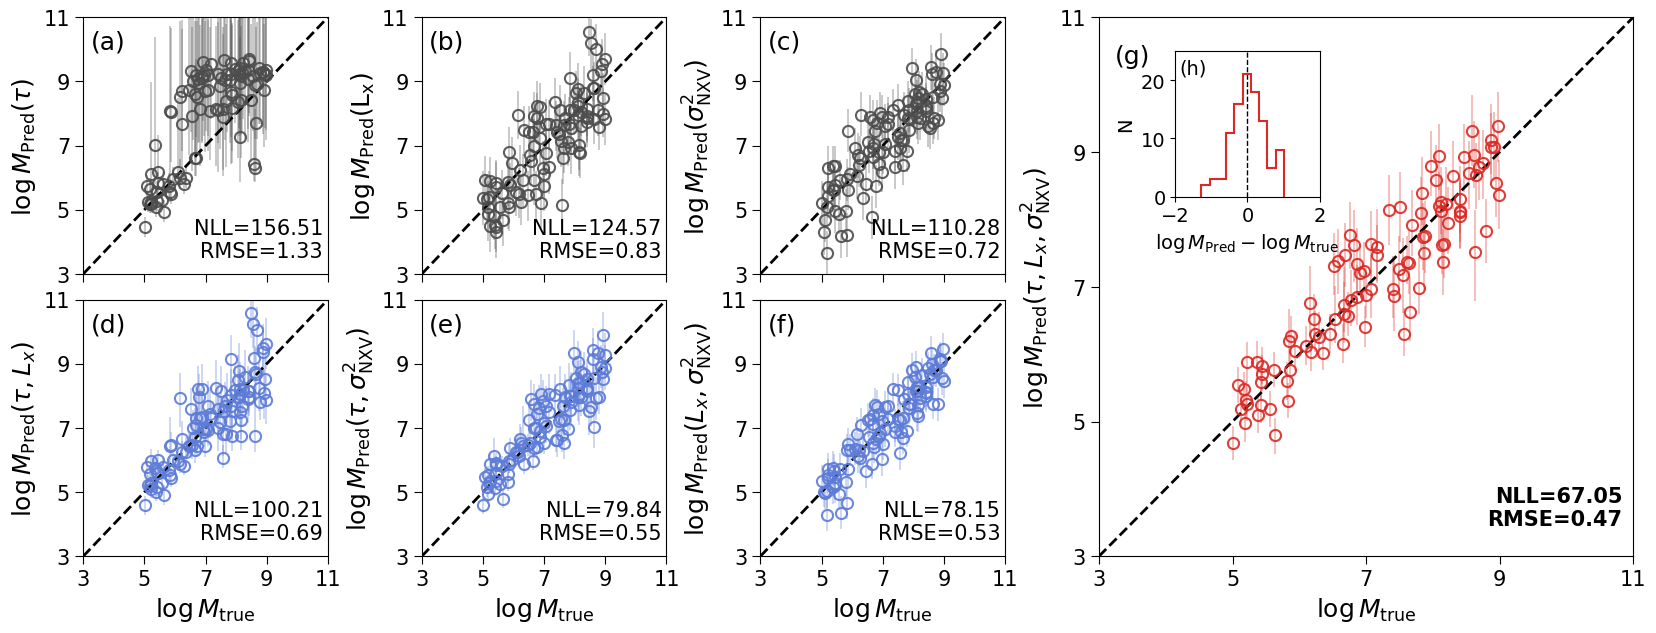

In [7]:
df_mock_100 = df_mock.sample(n=100, random_state=0).reset_index(drop=True)
order = [
    ("LOGMBH_0", "LOGMBH_0_ERR_LO", "LOGMBH_0_ERR_HI", r"$\log M_{\rm Pred}(\tau)$"),
    ("LOGMBH_1", "LOGMBH_1_ERR_LO", "LOGMBH_1_ERR_HI", r"$\log M_{\rm Pred}(\rm L_x)$"),
    ("LOGMBH_2", "LOGMBH_2_ERR_LO", "LOGMBH_2_ERR_HI", r"$\log M_{\rm Pred}(\sigma^2_{\rm NXV})$"),
    ("LOGMBH_3", "LOGMBH_3_ERR_LO", "LOGMBH_3_ERR_HI", r"$\log M_{\rm Pred}(\tau, L_x)$"),
    ("LOGMBH_4", "LOGMBH_4_ERR_LO", "LOGMBH_4_ERR_HI", r"$\log M_{\rm Pred}(\tau, \sigma^2_{\rm NXV})$"),
    ("LOGMBH_5", "LOGMBH_5_ERR_LO", "LOGMBH_5_ERR_HI", r"$\log M_{\rm Pred}(L_x, \sigma^2_{\rm NXV})$"),
    ("LOGMBH_6", "LOGMBH_6_ERR_LO", "LOGMBH_6_ERR_HI", r"$\log M_{\rm Pred}(\tau,L_x,\sigma^2_{\rm NXV})$")
]

colors = ["#4D4D4D"]*3 + ["#5D7CD7"]*3 + ["#DA2A25"]
panel_labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)", "(g)"]


fig = plt.figure(figsize=(20, 7))
gs = gridspec.GridSpec(2, 5, figure=fig, wspace=0.4, hspace=0.1, width_ratios=[1,1,1,1,0.8])

axes = []
axes.append(fig.add_subplot(gs[0, 0]))
axes.append(fig.add_subplot(gs[0, 1]))
axes.append(fig.add_subplot(gs[0, 2]))
axes.append(fig.add_subplot(gs[1, 0]))
axes.append(fig.add_subplot(gs[1, 1]))
axes.append(fig.add_subplot(gs[1, 2]))
axes.append(fig.add_subplot(gs[:, 3:]))

for i, ax in enumerate(axes):
    ycol, lo, hi, ylabel = order[i]
    color = colors[i]

    y_pred = df_mock_100[ycol].values
    y_err = 0.5*(df_mock_100[lo].values + df_mock_100[hi].values)
    y_true = df_mock_100["LOGMBH_TRUE"].values

    ax.errorbar(
    y_true, y_pred,
    yerr=[df_mock_100[lo], df_mock_100[hi]],
    fmt="o",
    markersize=8,
    markeredgewidth=1.5, 
    markerfacecolor="none",
    markeredgecolor=color,
    linewidth=1.4,
    alpha=0.9,
    color=color)
    
    ax.plot([3, 11], [3, 11], "k--", linewidth=2)
    ax.set_xlim(3, 10.5)
    ax.set_ylim(3, 10.5)
    ax.set_xticks(np.arange(3, 12, 2)); ax.set_yticks(np.arange(3, 12, 2))
    ax.tick_params(axis='both', which='major', labelsize=15, length=6)

    if i >= 3: ax.set_xlabel(r"$\log M_{\rm true}$", fontsize=18)
    else: ax.set_xticklabels([])
    
    ax.set_ylabel(ylabel, fontsize=18)

    nll = 0.5*np.sum(((y_true - y_pred)/y_err)**2 + np.log(2*np.pi*y_err**2))
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    ax.text(0.03, 0.95, panel_labels[i], fontsize=18, 
                  ha='left', va='top', transform=ax.transAxes)
    txt = ax.text(0.98, 0.05, f"NLL={nll:.2f}\nRMSE={rmse:.2f}",
                  fontsize=15, color='black', ha='right', va='bottom', transform=ax.transAxes)
    
    for c in ax.collections:
        c.set_alpha(0.3)
axes[-1].texts[-1].set_fontweight("bold")
ax_main = axes[-1]
ax_inset = inset_axes(ax_main, width="30%", height="30%", loc='upper left', 
                      bbox_to_anchor=(0.13, 0.05, 0.9, 0.9), bbox_transform=ax_main.transAxes)
ax_inset.axvline(0, color='k', ls='--',lw=1)
ax_inset.text(0.03, 0.95, "(h)", fontsize=14,
            ha='left', va='top', transform=ax_inset.transAxes)             
ax_inset.hist(y_pred - y_true, bins=10, color="#DA2A25", histtype='step',lw=1.5)
ax_inset.set_xlabel(r"$\log M_{\rm Pred} - \log M_{\rm true}$", fontsize=14)
ax_inset.set_ylabel(r"N", fontsize=14)
ax_inset.tick_params(axis='both', labelsize=14)
ax_inset.set_xlim(-2,2)
ax_inset.set_ylim(0,25)
fig.savefig(paper_dir / "fig1.png", bbox_inches='tight')

## Uncertainties and Covariance (Appendix B)

### Uncertainties

In [8]:
ASSUMED_RELATION_SCATTERS = [0.1, 0.3, 0.6, 0.9]

def estimate_one_mock_scatter(task):
    assumed_scatter, index, par = task
    rows = []
    for j, (use_tau, use_lx, use_nxv) in enumerate(COMBINATIONS):
        estimator = MassEstimator()
        if use_tau:
            estimator.add_tau(
                par["LOGTAU_EST"], par["baseline"], par["ncadence"],
                func_LOGTAU, assumed_scatter,
                args=[par["z"]], args_err=[0],
            )
        if use_lx:
            estimator.add_param(
                par["LOGLX_EST"], 0.20, func_LOGLX, assumed_scatter,
            )
        if use_nxv:
            estimator.add_Mparam(
                func_M_log_sigma2_NXV, assumed_scatter,
                args=[par["log_sigma2_NXV_EST"]], args_err=[0.02],
            )
        samples = estimator.estimate(pool_size=1, progress=False)
        q16, median, q84 = np.percentile(samples, [16, 50, 84])
        rows.append({
            "ASSUMED_RELATION_SCATTER": assumed_scatter,
            "mock_index": index,
            "combination": j,
            "LOGMBH_TRUE": par["LOGMBH_TRUE"],
            "LOGMBH_PRED": median,
            "LOGMBH_ERR_LO": median - q16,
            "LOGMBH_ERR_HI": q84 - median,
        })
    return rows

In [9]:

# tasks = [
#     (assumed_scatter, index, row.to_dict())
#     for assumed_scatter in ASSUMED_RELATION_SCATTERS
#     for index, row in df_mock.iterrows()
# ]

# n_processes = min(12, max(1, len(tasks)))

# with mp.Pool(processes=n_processes) as pool:
#     nested_results = list(
#         tqdm(
#             pool.imap_unordered(
#                 estimate_one_mock_scatter,
#                 tasks,
#                 chunksize=1,
#             ),
#             total=len(tasks),
#             desc="Testing assumed intrinsic scatter on mock sample",
#         )
#     )

# df_mock_scatter_test = pandas.DataFrame(
#     [row for result in nested_results for row in result]
# ).sort_values(
#     ["ASSUMED_RELATION_SCATTER", "mock_index", "combination"]
# ).reset_index(drop=True)

# df_mock_scatter_test.to_pickle(
#     paper_dir / "data" / "df_mock_scatter_test.pkl"
# )
# df_mock_scatter_test

In [10]:
df_mock_scatter_test = pandas.read_pickle(
    paper_dir / "data" / "df_mock_scatter_test.pkl"
)
df_mock_correct_scatter = pandas.read_pickle(mock_path)

proxy_labels = {
    0: r"$\tau$",
    1: r"$L_{\rm X}$",
    2: r"$\sigma^2_{\rm NXV}$",
    3: r"$\tau, L_{\rm X}$",
    4: r"$\tau, \sigma^2_{\rm NXV}$",
    5: r"$L_{\rm X}, \sigma^2_{\rm NXV}$",
    6: r"$\tau, L_{\rm X}, \sigma^2_{\rm NXV}$",
}

table_data = df_mock_scatter_test.copy()
table_data["squared_error"] = (
    table_data["LOGMBH_PRED"] - table_data["LOGMBH_TRUE"]
) ** 2
table_data["signed_error"] = (
    table_data["LOGMBH_PRED"] - table_data["LOGMBH_TRUE"]
)
table_data["covered_68"] = (
    (table_data["LOGMBH_TRUE"]
     >= table_data["LOGMBH_PRED"] - table_data["LOGMBH_ERR_LO"])
    & (table_data["LOGMBH_TRUE"]
       <= table_data["LOGMBH_PRED"] + table_data["LOGMBH_ERR_HI"])
)

summary_long = (
    table_data.groupby(
        ["combination", "ASSUMED_RELATION_SCATTER"], sort=True
    )
    .agg(
        RMSE=("squared_error", lambda x: np.sqrt(x.mean())),
        Bias=("signed_error", "mean"),
        C68=("covered_68", "mean"),
    )
)

assumed_scatter_table = summary_long.unstack("ASSUMED_RELATION_SCATTER")
assumed_scatter_table = assumed_scatter_table.swaplevel(0, 1, axis=1)
assumed_scatter_table = assumed_scatter_table.reindex(
    columns=pandas.MultiIndex.from_product(
        [ASSUMED_RELATION_SCATTERS, ["RMSE", "Bias", "C68"]],
        names=["Relation-scatter setting", "Metric"],
    )
)

correct_scatter_rows = []
for combination in range(7):
    true_mass = df_mock_correct_scatter["LOGMBH_TRUE"]
    predicted_mass = df_mock_correct_scatter[f"LOGMBH_{combination}"]
    error_lo = df_mock_correct_scatter[f"LOGMBH_{combination}_ERR_LO"]
    error_hi = df_mock_correct_scatter[f"LOGMBH_{combination}_ERR_HI"]
    correct_scatter_rows.append({
        "combination": combination,
        "RMSE": np.sqrt(np.mean((predicted_mass - true_mass) ** 2)),
        "Bias": np.mean(predicted_mass - true_mass),
        "C68": np.mean(
            (true_mass >= predicted_mass - error_lo)
            & (true_mass <= predicted_mass + error_hi)
        ),
    })
correct_scatter_table = (
    pandas.DataFrame(correct_scatter_rows).set_index("combination")
)
correct_scatter_table.columns = pandas.MultiIndex.from_product(
    [[r"Correct $\sigma_\epsilon$"], ["RMSE", "Bias", "C68"]],
    names=["Relation-scatter setting", "Metric"],
)

# Put the correctly specified baseline immediately after the row label.
summary_table = pandas.concat(
    [correct_scatter_table, assumed_scatter_table], axis=1
)
summary_table.index = summary_table.index.map(proxy_labels)
summary_table.index.name = "Parameters"

def emphasize_best(row):
    styles = pandas.Series("", index=row.index)
    rmse_columns = [col for col in row.index if col[1] == "RMSE"]
    bias_columns = [col for col in row.index if col[1] == "Bias"]
    c68_columns = [col for col in row.index if col[1] == "C68"]
    styles[row[rmse_columns].idxmin()] = "font-weight: bold"
    styles[row[bias_columns].abs().idxmin()] = "font-weight: bold"
    styles[(row[c68_columns] - 0.68).abs().idxmin()] = "font-weight: bold"
    return styles

table_style = (
    summary_table.style
    .format("{:.3f}")
    .apply(emphasize_best, axis=1)
    .set_caption(
        "Mock-sample mass recovery under correct and assumed relation scatters"
    )
    .set_table_styles([
        {"selector": "caption", "props": [
            ("font-weight", "bold"), ("font-size", "13pt"),
            ("caption-side", "top"), ("text-align", "left"),
        ]},
        {"selector": "th", "props": [
            ("background-color", "#f2f2f2"),
            ("border-bottom", "1px solid #777"),
        ]},
        {"selector": "td", "props": [
            ("text-align", "center"), ("padding", "5px 10px"),
        ]},
    ])
)

summary_table

Relation-scatter setting              Correct $\sigma_\epsilon$            \
Metric                                                     RMSE      Bias   
Parameters                                                                  
$\tau$                                                 1.397671  0.826342   
$L_{\rm X}$                                            0.805102  0.007257   
$\sigma^2_{\rm NXV}$                                   0.715262 -0.055415   
$\tau, L_{\rm X}$                                      0.633801  0.084027   
$\tau, \sigma^2_{\rm NXV}$                             0.560217  0.034644   
$L_{\rm X}, \sigma^2_{\rm NXV}$                        0.527770 -0.028062   
$\tau, L_{\rm X}, \sigma^2_{\rm NXV}$                  0.443202  0.009445   

Relation-scatter setting                           0.1                   \
Metric                                   C68      RMSE      Bias    C68   
Parameters                                                                
$\tau$                                 0.677  1.408986  0.636197  0.485   
$L_{\rm X}$                            0.676  0.806821  0.007753  0.242   
$\sigma^2_{\rm NXV}$                   0.649  0.712659 -0.055260  0.114   
$\tau, L_{\rm X}$                      0.678  0.668740  0.064738  0.247   
$\tau, \sigma^2_{\rm NXV}$             0.645  0.632963 -0.009966  0.115   
$L_{\rm X}, \sigma^2_{\rm NXV}$        0.657  0.620411 -0.045994  0.123   
$\tau, L_{\rm X}, \sigma^2_{\rm NXV}$  0.650  0.556407 -0.012089  0.121   

Relation-scatter setting                    0.3                        0.6  \
Metric                                     RMSE      Bias    C68      RMSE   
Parameters                                                                   
$\tau$                                 1.402957  0.770668  0.623  1.395558   
$L_{\rm X}$                            0.806022  0.008235  0.381  0.807838   
$\sigma^2_{\rm NXV}$                   0.713101 -0.055220  0.323  0.711991   
$\tau, L_{\rm X}$                      0.656988  0.057146  0.423  0.651715   
$\tau, \sigma^2_{\rm NXV}$             0.591210 -0.001130  0.367  0.581744   
$L_{\rm X}, \sigma^2_{\rm NXV}$        0.536927 -0.032376  0.341  0.529533   
$\tau, L_{\rm X}, \sigma^2_{\rm NXV}$  0.463119 -0.008406  0.354  0.456517   

Relation-scatter setting                                     0.9            \
Metric                                     Bias    C68      RMSE      Bias   
Parameters                                                                   
$\tau$                                 0.904314  0.765  1.360714  0.947698   
$L_{\rm X}$                            0.008834  0.622  0.806476  0.006039   
$\sigma^2_{\rm NXV}$                  -0.053102  0.599  0.717014 -0.054712   
$\tau, L_{\rm X}$                      0.076191  0.687  0.655510  0.113240   
$\tau, \sigma^2_{\rm NXV}$             0.012115  0.647  0.579158  0.037697   
$L_{\rm X}, \sigma^2_{\rm NXV}$       -0.029115  0.602  0.530249 -0.027653   
$\tau, L_{\rm X}, \sigma^2_{\rm NXV}$ -0.002032  0.636  0.457496  0.010005   

Relation-scatter setting                      
Metric                                   C68  
Parameters                                    
$\tau$                                 0.866  
$L_{\rm X}$                            0.808  
$\sigma^2_{\rm NXV}$                   0.791  
$\tau, L_{\rm X}$                      0.842  
$\tau, \sigma^2_{\rm NXV}$             0.829  
$L_{\rm X}, \sigma^2_{\rm NXV}$        0.801  
$\tau, L_{\rm X}, \sigma^2_{\rm NXV}$  0.828

### Covariance

In [11]:
COVARIANCE_RHOS = [-0.6, -0.3, 0.3, 0.6]

COVARIANCE_PAIRS = {
    "tau_lx": {"indices": (0, 1), "combination": 3},
    "tau_nxv": {"indices": (0, 2), "combination": 4},
    "lx_nxv": {"indices": (1, 2), "combination": 5},
}

# Keep the sample properties and all generative settings identical to the
# original mock test. Only the relation-scatter correlation is changed.
df_mock_cov_base = df_mock.copy()
n_mock_cov = len(df_mock_cov_base)
mock_indices_cov = df_mock_cov_base.index.to_numpy()
mass_cov = df_mock_cov_base["LOGMBH_TRUE"].to_numpy(dtype=float)
baseline_cov = df_mock_cov_base["baseline"].to_numpy(dtype=float)
ncadence_cov = df_mock_cov_base["ncadence"].to_numpy(dtype=float)
redshift_cov = df_mock_cov_base["z"].to_numpy(dtype=float)


rng_cov = np.random.default_rng(84)
base_relation_scatter_draws = rng_cov.standard_normal((n_mock_cov, 3))
base_measurement_error_draws = rng_cov.standard_normal((n_mock_cov, 3))

mean_log_tau0_cov = func_LOGTAU(mass_cov, redshift_cov)

mean_log_tau_cov, measurement_sigma_tau_cov = log_tau0_to_log_tau1(
    mean_log_tau0_cov, baseline_cov, ncadence_cov
)
mean_lx_cov = func_LOGLX(mass_cov)
mean_log_nxv_cov = np.log10(0.005) + (7.41 - mass_cov) / 0.94

delta_tau_measurement = (
    measurement_sigma_tau_cov * base_measurement_error_draws[:, 0]
)
delta_lx_measurement = 0.20 * base_measurement_error_draws[:, 1]
delta_log_nxv_measurement = 0.02 * base_measurement_error_draws[:, 2]

covariance_mock_frames = []
for pair_name, pair_config in COVARIANCE_PAIRS.items():
    first, second = pair_config["indices"]
    
    for rho in COVARIANCE_RHOS:
        correlated_relation_scatter_draws = base_relation_scatter_draws.copy()
        correlated_relation_scatter_draws[:, second] = (
            rho * base_relation_scatter_draws[:, first]
            + np.sqrt(1.0 - rho**2) * base_relation_scatter_draws[:, second]
        )

        delta_tau_relation = 0.40 * correlated_relation_scatter_draws[:, 0]
        delta_lx_relation = 0.70 * correlated_relation_scatter_draws[:, 1]
        delta_log_nxv_relation = (
            (0.70 / 0.94) * correlated_relation_scatter_draws[:, 2]
        )
        relation_residuals = np.column_stack([
            delta_tau_relation,
            delta_lx_relation,
            delta_log_nxv_relation,
        ])

        frame = pandas.DataFrame({
            "pair": pair_name,
            "rho_target": rho,
            "mock_index": mock_indices_cov,
            "LOGMBH_TRUE": mass_cov,
            "baseline": baseline_cov,
            "ncadence": ncadence_cov,
            "z": redshift_cov,
            "LOGTAU_EST": (
                mean_log_tau_cov
                + delta_tau_relation
                + delta_tau_measurement
            ),
            "LOGLX_EST": (
                mean_lx_cov
                + delta_lx_relation
                + delta_lx_measurement
            ),
            "log_sigma2_NXV_EST": (
                mean_log_nxv_cov
                + delta_log_nxv_relation
                + delta_log_nxv_measurement
            ),
            "delta_tau_relation": delta_tau_relation,
            "delta_lx_relation": delta_lx_relation,
            "delta_log_nxv_relation": delta_log_nxv_relation,
        })
        frame["rho_realized"] = np.corrcoef(
            relation_residuals[:, first],
            relation_residuals[:, second],
        )[0, 1]
        covariance_mock_frames.append(frame)

df_mock_covariance = pandas.concat(
    covariance_mock_frames, ignore_index=True
)


In [12]:
def estimate_covariance_model(par, combination):
    use_tau, use_lx, use_nxv = COMBINATIONS[combination]
    estimator = MassEstimator()
    if use_tau:
        estimator.add_tau(
            par["LOGTAU_EST"], par["baseline"], par["ncadence"],
            func_LOGTAU, 0.40, args=[par["z"]], args_err=[0],
        )
    if use_lx:
        estimator.add_param(
            par["LOGLX_EST"], 0.20, func_LOGLX, 0.70,
        )
    if use_nxv:
        estimator.add_Mparam(
            func_M_log_sigma2_NXV, 0.70,
            args=[par["log_sigma2_NXV_EST"]], args_err=[0.02],
        )
    samples = estimator.estimate(pool_size=1, progress=False)
    q16, median, q84 = np.percentile(samples, [16, 50, 84])
    return median, median - q16, q84 - median

def estimate_one_covariance_mock(task):
    task_number, par = task
    pair_name = par["pair"]
    two_proxy_combination = COVARIANCE_PAIRS[pair_name]["combination"]
    rows = []
    for model_offset, (model, combination) in enumerate([
        ("two_proxy", two_proxy_combination),
        ("three_proxy", 6),
    ]):
        median, err_lo, err_hi = estimate_covariance_model(par, combination)
        rows.append({
            "pair": pair_name,
            "rho_target": par["rho_target"],
            "rho_realized": par["rho_realized"],
            "mock_index": par["mock_index"],
            "model": model,
            "combination": combination,
            "LOGMBH_TRUE": par["LOGMBH_TRUE"],
            "LOGMBH_PRED": median,
            "LOGMBH_ERR_LO": err_lo,
            "LOGMBH_ERR_HI": err_hi,
        })
    return rows

In [13]:
# covariance_tasks = [
#     (task_number, row.to_dict())
#     for task_number, (_, row) in enumerate(df_mock_covariance.iterrows())
# ]
# n_processes_covariance = min(12, max(1, len(covariance_tasks)))
# with mp.Pool(processes=n_processes_covariance) as pool:
#     nested_covariance_results = list(
#         tqdm(
#             pool.imap_unordered(
#                 estimate_one_covariance_mock, covariance_tasks, chunksize=1
#             ),
#             total=len(covariance_tasks),
#             desc="Observable-space covariance experiment",
#         )
#     )

# df_covariance_test = pandas.DataFrame(
#     [row for result in nested_covariance_results for row in result]
# ).sort_values(
#     ["pair", "rho_target", "mock_index", "model"]
# ).reset_index(drop=True)
# df_covariance_test.to_pickle(
#     paper_dir / "data" / "df_mock_covariance_test.pkl"
# )
# df_covariance_test

In [14]:
# Reload the completed covariance run so this table is independently reproducible.
df_covariance_test = pandas.read_pickle(
    paper_dir / "data" / "df_mock_covariance_test.pkl"
)

covariance_table_data = df_covariance_test.copy()
covariance_table_data["squared_error"] = (
    covariance_table_data["LOGMBH_PRED"]
    - covariance_table_data["LOGMBH_TRUE"]
) ** 2
covariance_table_data["signed_error"] = (
    covariance_table_data["LOGMBH_PRED"]
    - covariance_table_data["LOGMBH_TRUE"]
)
covariance_table_data["covered_68"] = (
    (covariance_table_data["LOGMBH_TRUE"]
     >= covariance_table_data["LOGMBH_PRED"]
     - covariance_table_data["LOGMBH_ERR_LO"])
    & (covariance_table_data["LOGMBH_TRUE"]
       <= covariance_table_data["LOGMBH_PRED"]
       + covariance_table_data["LOGMBH_ERR_HI"])
)

covariance_summary_long = (
    covariance_table_data.groupby(
        ["pair", "model", "rho_target"], sort=False
    )
    .agg(
        RMSE=("squared_error", lambda x: np.sqrt(x.mean())),
        Bias=("signed_error", "mean"),
        C68=("covered_68", "mean"),
    )
)

pair_order = ["tau_lx", "tau_nxv", "lx_nxv"]
model_order = ["two_proxy", "three_proxy"]
rho_order = COVARIANCE_RHOS
row_order = pandas.MultiIndex.from_tuples(
    [
        (pair, model)
        for model in model_order
        for pair in pair_order
    ],
    names=["Correlated pair", "Model"],
)
column_order = pandas.MultiIndex.from_product(
    [rho_order, ["RMSE", "Bias", "C68"]],
    names=[r"Target $\rho$", "Metric"],
)

covariance_summary_table = covariance_summary_long.unstack("rho_target")
covariance_summary_table = covariance_summary_table.swaplevel(0, 1, axis=1)
covariance_summary_table = covariance_summary_table.reindex(
    index=row_order, columns=column_order
)

pair_labels = {
    "tau_lx": r"$\tau$--$L_{\rm X}$",
    "tau_nxv": r"$\tau$--$\sigma^2_{\rm NXV}$",
    "lx_nxv": r"$L_{\rm X}$--$\sigma^2_{\rm NXV}$",
}
two_proxy_labels = {
    "tau_lx": r"$\tau, L_{\rm X}$",
    "tau_nxv": r"$\tau, \sigma^2_{\rm NXV}$",
    "lx_nxv": r"$L_{\rm X}, \sigma^2_{\rm NXV}$",
}
three_proxy_label = r"$\tau, L_{\rm X}, \sigma^2_{\rm NXV}$"
covariance_summary_table.index = pandas.MultiIndex.from_tuples(
    [
        (
            two_proxy_labels[pair] if model == "two_proxy"
            else three_proxy_label,
            pair_labels[pair],
        )
        for pair, model in covariance_summary_table.index
    ],
    names=["Parameters", "Correlated pair"],
)

def emphasize_covariance_row(row):
    styles = pandas.Series("", index=row.index)
    rmse_columns = [column for column in row.index if column[1] == "RMSE"]
    bias_columns = [column for column in row.index if column[1] == "Bias"]
    c68_columns = [column for column in row.index if column[1] == "C68"]
    styles[row[rmse_columns].idxmin()] = "font-weight: bold"
    styles[row[bias_columns].abs().idxmin()] = "font-weight: bold"
    styles[(row[c68_columns] - 0.68).abs().idxmin()] = "font-weight: bold"
    return styles

covariance_table_style = (
    covariance_summary_table.style
    .format("{:.3f}")
    .apply(emphasize_covariance_row, axis=1)
    .set_caption(
        "Mass-recovery performance with correlated observable residuals"
    )
    .set_table_styles([
        {"selector": "caption", "props": [
            ("font-weight", "bold"), ("font-size", "13pt"),
            ("caption-side", "top"), ("text-align", "left"),
        ]},
        {"selector": "th", "props": [
            ("background-color", "#f2f2f2"),
            ("border-bottom", "1px solid #777"),
        ]},
        {"selector": "td", "props": [
            ("text-align", "center"), ("padding", "5px 10px"),
        ]},
    ])
)

# Numeric table retained for optional CSV or LaTeX export.
covariance_summary_table


Target $\rho$                                                                -0.6  \
Metric                                                                       RMSE   
Parameters                            Correlated pair                               
$\tau, L_{\rm X}$                     $\tau$--$L_{\rm X}$                0.577489   
$\tau, \sigma^2_{\rm NXV}$            $\tau$--$\sigma^2_{\rm NXV}$       0.624699   
$L_{\rm X}, \sigma^2_{\rm NXV}$       $L_{\rm X}$--$\sigma^2_{\rm NXV}$  0.667824   
$\tau, L_{\rm X}, \sigma^2_{\rm NXV}$ $\tau$--$L_{\rm X}$                0.411624   
                                      $\tau$--$\sigma^2_{\rm NXV}$       0.488927   
                                      $L_{\rm X}$--$\sigma^2_{\rm NXV}$  0.547154   

Target $\rho$                                                                      \
Metric                                                                       Bias   
Parameters                            Correlated pair                               
$\tau, L_{\rm X}$                     $\tau$--$L_{\rm X}$                0.129545   
$\tau, \sigma^2_{\rm NXV}$            $\tau$--$\sigma^2_{\rm NXV}$       0.029842   
$L_{\rm X}, \sigma^2_{\rm NXV}$       $L_{\rm X}$--$\sigma^2_{\rm NXV}$  0.028785   
$\tau, L_{\rm X}, \sigma^2_{\rm NXV}$ $\tau$--$L_{\rm X}$                0.043635   
                                      $\tau$--$\sigma^2_{\rm NXV}$       0.027475   
                                      $L_{\rm X}$--$\sigma^2_{\rm NXV}$  0.058134   

Target $\rho$                                                                   \
Metric                                                                     C68   
Parameters                            Correlated pair                            
$\tau, L_{\rm X}$                     $\tau$--$L_{\rm X}$                0.752   
$\tau, \sigma^2_{\rm NXV}$            $\tau$--$\sigma^2_{\rm NXV}$       0.616   
$L_{\rm X}, \sigma^2_{\rm NXV}$       $L_{\rm X}$--$\sigma^2_{\rm NXV}$  0.568   
$\tau, L_{\rm X}, \sigma^2_{\rm NXV}$ $\tau$--$L_{\rm X}$                0.725   
                                      $\tau$--$\sigma^2_{\rm NXV}$       0.620   
                                      $L_{\rm X}$--$\sigma^2_{\rm NXV}$  0.602   

Target $\rho$                                                                -0.3  \
Metric                                                                       RMSE   
Parameters                            Correlated pair                               
$\tau, L_{\rm X}$                     $\tau$--$L_{\rm X}$                0.610264   
$\tau, \sigma^2_{\rm NXV}$            $\tau$--$\sigma^2_{\rm NXV}$       0.587248   
$L_{\rm X}, \sigma^2_{\rm NXV}$       $L_{\rm X}$--$\sigma^2_{\rm NXV}$  0.603137   
$\tau, L_{\rm X}, \sigma^2_{\rm NXV}$ $\tau$--$L_{\rm X}$                0.428561   
                                      $\tau$--$\sigma^2_{\rm NXV}$       0.465956   
                                      $L_{\rm X}$--$\sigma^2_{\rm NXV}$  0.496303   

Target $\rho$                                                                      \
Metric                                                                       Bias   
Parameters                            Correlated pair                               
$\tau, L_{\rm X}$                     $\tau$--$L_{\rm X}$                0.118378   
$\tau, \sigma^2_{\rm NXV}$            $\tau$--$\sigma^2_{\rm NXV}$       0.038528   
$L_{\rm X}, \sigma^2_{\rm NXV}$       $L_{\rm X}$--$\sigma^2_{\rm NXV}$  0.021269   
$\tau, L_{\rm X}, \sigma^2_{\rm NXV}$ $\tau$--$L_{\rm X}$                0.040403   
                                      $\tau$--$\sigma^2_{\rm NXV}$       0.029523   
                                      $L_{\rm X}$--$\sigma^2_{\rm NXV}$  0.046407   

Target $\rho$                                                                   \
Metric                                                                     C68   
Parameters                       

In [15]:
bs = chr(92)

def latex_metric_cells(row, settings):
    cells = []
    for setting in settings:
        for metric in ["RMSE", "C68"]:
            column = (setting, metric)
            value = f"{row[column]:.2f}"
            cells.append(value)
    return cells

correct_setting = summary_table.columns.get_level_values(0)[0]
correct_header = r"Correct $\sigma_\epsilon$"
scatter_settings = [correct_setting] + ASSUMED_RELATION_SCATTERS
scatter_headers = [correct_header] + [
    rf"$\sigma_\epsilon={value:.1f}$"
    for value in ASSUMED_RELATION_SCATTERS
]
rho_settings = COVARIANCE_RHOS
rho_headers = [f"{value:.1f}" for value in rho_settings]

latex_lines = [
    f"{bs}begin{{table*}}[t]",
    f"{bs}centering",
    f"{bs}caption{{Mock-sample tests of relation-scatter and covariance assumptions.}}",
    f"{bs}phantomsection",
    f"{bs}label{{tabB}}",
    f"{bs}small",
    f"{bs}renewcommand{{{bs}arraystretch}}{{1.08}}",
    f"{bs}setlength{{{bs}tabcolsep}}{{3pt}}",
    # One shared 11-column table spanning the full text width.
    f"{bs}begin{{tabular*}}{{{bs}textwidth}}{{@{{{bs}extracolsep{{{bs}fill}}}}lrrrrrrrrrr@{{}}}}",
    f"{bs}multicolumn{{11}}{{l}}{{{bs}textbf{{Relation-scatter assumption}}}} {bs}{bs}",
    f"{bs}hline",
]

panel_a_header = ["Indicators"]
panel_a_header += [
    f"{bs}multicolumn{{2}}{{c}}{{{header}}}" for header in scatter_headers
]
latex_lines.append(" & ".join(panel_a_header) + f" {bs}{bs}")
panel_a_metrics = [""]
panel_a_metrics += [
    item for _ in scatter_settings
    for item in ["RMSE", f"$C_{{68}}$"]
]
latex_lines.append(" & ".join(panel_a_metrics) + f" {bs}{bs}")
latex_lines.append(f"{bs}hline")
for proxy, row in summary_table.iterrows():
    cells = [proxy]
    cells += latex_metric_cells(row, scatter_settings)
    latex_lines.append(" & ".join(cells) + f" {bs}{bs}")
latex_lines += [
    f"{bs}hline",
    f"{bs}multicolumn{{11}}{{l}}{{{bs}textbf{{Residual covariance}}}} {bs}{bs}",
    f"{bs}hline",
]
# Align Indicators with the first section's row label. Correlated pair spans and
# is centered across the same two columns as Correct sigma_epsilon.
panel_b_header = [
    "Indicators",
    f"{bs}multicolumn{{2}}{{c}}{{Correlated pair}}",
]
panel_b_header += [
    f"{bs}multicolumn{{2}}{{c}}{{${bs}rho={header}$}}" for header in rho_headers
]
latex_lines.append(" & ".join(panel_b_header) + f" {bs}{bs}")
panel_b_metrics = [
    "", f"{bs}multicolumn{{2}}{{c}}{{}}",
]
panel_b_metrics += [
    item for _ in rho_settings
    for item in ["RMSE", f"$C_{{68}}$"]
]
latex_lines.append(" & ".join(panel_b_metrics) + f" {bs}{bs}")
latex_lines.append(f"{bs}hline")
for (proxies, pair), row in covariance_summary_table.iterrows():
    cells = [
        proxies, f"{bs}multicolumn{{2}}{{c}}{{{pair}}}",
    ]
    cells += latex_metric_cells(row, rho_settings)
    latex_lines.append(" & ".join(cells) + f" {bs}{bs}")
latex_lines += [
    f"{bs}hline",
    f"{bs}end{{tabular*}}",
    f"{bs}justifying",
    f"{bs}tablecomments{{",
    f"Both tests use a mock sample containing 1000 sources. Correct ${bs}sigma_{bs}epsilon$ denotes the parameter-specific generating relation scatters. ${bs}rho$ is the correlation between observable-space relation residuals.",
    "}",
    f"{bs}end{{table*}}",
]

combined_latex_table = "\n".join(latex_lines)
latex_output_path = paper_dir / "TableB1.tex"
latex_output_path.write_text(combined_latex_table, encoding="utf-8")
print(combined_latex_table)
print(f"\nSaved to: {latex_output_path}")


\begin{table*}[t]
\centering
\caption{Mock-sample tests of relation-scatter and covariance assumptions.}
\phantomsection
\label{tabB}
\small
\renewcommand{\arraystretch}{1.08}
\setlength{\tabcolsep}{3pt}
\begin{tabular*}{\textwidth}{@{\extracolsep{\fill}}lrrrrrrrrrr@{}}
\multicolumn{11}{l}{\textbf{Relation-scatter assumption}} \\
\hline
Indicators & \multicolumn{2}{c}{Correct $\sigma_\epsilon$} & \multicolumn{2}{c}{$\sigma_\epsilon=0.1$} & \multicolumn{2}{c}{$\sigma_\epsilon=0.3$} & \multicolumn{2}{c}{$\sigma_\epsilon=0.6$} & \multicolumn{2}{c}{$\sigma_\epsilon=0.9$} \\
 & RMSE & $C_{68}$ & RMSE & $C_{68}$ & RMSE & $C_{68}$ & RMSE & $C_{68}$ & RMSE & $C_{68}$ \\
\hline
$\tau$ & 1.40 & 0.68 & 1.41 & 0.48 & 1.40 & 0.62 & 1.40 & 0.77 & 1.36 & 0.87 \\
$L_{\rm X}$ & 0.81 & 0.68 & 0.81 & 0.24 & 0.81 & 0.38 & 0.81 & 0.62 & 0.81 & 0.81 \\
$\sigma^2_{\rm NXV}$ & 0.72 & 0.65 & 0.71 & 0.11 & 0.71 & 0.32 & 0.71 & 0.60 & 0.72 & 0.79 \\
$\tau, L_{\rm X}$ & 0.63 & 0.68 & 0.67 & 0.25 & 0.66 & 0.42 & 0

# REAL (Section 3.2)

In [16]:
dfx = pandas.read_pickle(paper_dir / "data" / "dfx_selected.pkl")
dfx["LOGMBH_ERR"] = dfx["LOGMBH_ERR"].fillna(0.1)
dfx["lumin_err"] = dfx.lumin_err/(dfx.lumin*np.log(10))
dfx["lumin"] = np.log10(dfx.lumin)+44
for i,par in dfx.iterrows():
    x = par.x
    y = par.y
    yerr = par.yerr
    mu = np.mean(y)
    sigma2_NXV = 1/(len(x)*mu**2)*np.sum((y-mu)**2-yerr**2)
    sigma2_NXV_ERR = np.sqrt((np.sqrt(2/len(x))*(np.mean(yerr**2)/mu**2))**2+(np.sqrt(np.mean(yerr**2)/len(x))*(2*np.sqrt(sigma2_NXV)/mu))**2)
    dfx.at[i, "log_sigma2_NXV"] = np.log10(sigma2_NXV)
    dfx.at[i, "log_sigma2_NXV_ERR"] = sigma2_NXV_ERR/sigma2_NXV/np.log(10)
len(dfx), len(dfx.src_name.unique())

(399, 112)

In [17]:
def estimate_one_real(index, par):
    result = {}

    for j, (use_tau, use_lx, use_nxv) in enumerate(COMBINATIONS):
        estimator = MassEstimator()

        if use_tau:
            estimator.add_tau(
                par["log_tau_mle"],
                par["baseline"],
                par["ncadence"],
                func_LOGTAU,
                0.40,
                args=[par["redshift"]],
                args_err=[0],
            )

        if use_lx:
            estimator.add_param(
                par["lumin"],
                par["lumin_err"],
                func_LOGLX,
                0.70,
            )

        if use_nxv:
            estimator.add_Mparam(
                func_M_log_sigma2_NXV,
                0.70,
                args=[par["log_sigma2_NXV"]],
                args_err=[par["log_sigma2_NXV_ERR"]],
            )

        samples = estimator.estimate(
            pool_size=1,
            progress=False,
        )

        q16, median, q84 = np.percentile(samples, [16, 50, 84])

        result[f"LOGMBH_{j}"] = median
        result[f"LOGMBH_{j}_ERR_HI"] = q84 - median
        result[f"LOGMBH_{j}_ERR_LO"] = median - q16

    return index, result
dfx_path = paper_dir / "data" / "dfx_MassEstimated_Real.pkl"

In [18]:
# def estimate_one_real_task(task):
#     return estimate_one_real(*task)
    
# tasks = [
#     (index, row.to_dict())
#     for index, row in dfx.iterrows()
# ]

# with mp.Pool(processes=12) as pool:
#     result_pairs = list(
#         tqdm(
#             pool.imap_unordered(
#                 estimate_one_real_task,
#                 tasks,
#                 chunksize=1,
#             ),
#             total=len(tasks),
#             desc="Estimating real sample",
#         )
#     )

# result_df = pandas.DataFrame.from_dict(
#     dict(result_pairs),
#     orient="index",
# ).reindex(dfx.index)

# dfx[result_df.columns] = result_df
# dfx.to_pickle(dfx_path)

# dfx

In [19]:
dfx = pandas.read_pickle(dfx_path)
dfx

,XID,obsid,expid,annulus,src_name,ra,dec,main_type,redshift,redshift_err_1,...,LOGMBH_3s_ERR_LO,LOGMBH_4s,LOGMBH_4s_ERR_HI,LOGMBH_4s_ERR_LO,LOGMBH_5s,LOGMBH_5s_ERR_HI,LOGMBH_5s_ERR_LO,LOGMBH_6s,LOGMBH_6s_ERR_HI,LOGMBH_6s_ERR_LO
0,8,0670130701,0,2.0,UGC 12163,340.663903,29.725347,Seyfert1,0.024285,NaN,...,0.178622,6.503037,0.121829,0.117695,6.985582,0.138691,0.135754,6.797881,0.119866,0.117210
1,9,0670130901,0,3.0,UGC 12163,340.663896,29.725359,Seyfert1,0.024285,NaN,...,0.178622,6.503037,0.121829,0.117695,6.985582,0.138691,0.135754,6.797881,0.119866,0.117210
2,10,0670130301,0,2.0,UGC 12163,340.663912,29.725349,Seyfert1,0.024285,NaN,...,0.178622,6.503037,0.121829,0.117695,6.985582,0.138691,0.135754,6.797881,0.119866,0.117210
3,11,0006810101,0,3.0,UGC 12163,340.664383,29.725545,Seyfert1,0.024285,NaN,...,0.178622,6.503037,0.121829,0.117695,6.985582,0.138691,0.135754,6.797881,0.119866,0.117210
4,12,0670130501,0,3.0,UGC 12163,340.663861,29.725103,Seyfert1,0.024285,NaN,...,0.178622,6.503037,0.121829,0.117695,6.985582,0.138691,0.135754,6.797881,0.119866,0.117210
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
394,2574,0852060101,0,0.0,LEDA 2816425,71.119982,12.353012,Seyfert1,0.089940,0.00076,...,0.532370,6.456967,0.296462,0.326238,7.120006,0.334668,0.317619,6.840770,0.327634,0.357513
395,2575,0852060301,0,1.0,Mrk 142,156.380331,51.676342,Seyfert1,0.044590,0.00002,...,0.586215,6.496991,0.478763,0.500933,6.933010,0.496095,0.454767,6.576497,0.441284,0.444356
396,2615,0863050201,0,0.0,ESO 33-2,73.993960,-75.541113,Seyfert2,0.018446,0.00050,...,0.347082,6.678420,0.474838,0.428127,6.839359,0.545599,0.487440,6.637244,0.332431,0.376343
397,2640,0881350101,0,0.0,IRAS 11119+3257,168.662043,32.692648,Seyfert1,0.187580,0.00002,...,0.690833,7.194279,0.501521,0.476490,7.503576,0.460821,0.478861,7.505898,0.461759,0.443742


LOGMBH            N = 112  median = 7.564  (source)
redshift          N = 112  median = -1.456  (source)
lumin             N = 399  median = 43.02  (exposure)
log_sigma2_NXV    N = 399  median = -1.68  (exposure)
log_tau_mle       N = 399  median = 4.003  (exposure)
baseline          N = 399  median = 0.707  (exposure)
ncadence          N = 399  median = 626  (exposure)
SNR_mle           N = 399  median = 0.2424  (exposure)


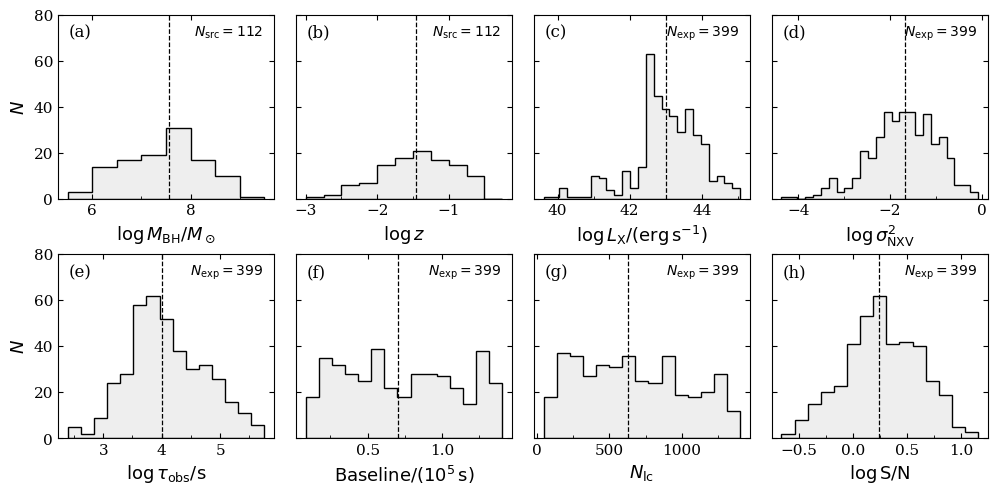

In [20]:


plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

source_df = (
    dfx.dropna(subset=["src_name"])
       .groupby("src_name", sort=False, as_index=False)
       .agg({
           "LOGMBH": "first",
           "redshift": "first",
       })
)

panels = [
    ("LOGMBH",         r"$\log M_{\rm BH}/M_\odot$",   "source"),
    ("redshift",       r"$\log z$",                    "source"),
    ("lumin",          r"$\log L_{\rm X}/({\rm erg\,s^{-1}})$", "exposure"),
    ("log_sigma2_NXV", r"$\log \sigma_{\rm NXV}^{2}$", "exposure"),
    ("log_tau_mle",    r"$\log \tau_{\rm obs}/{\rm s}$",          "exposure"),
    ("baseline",       r"${\rm Baseline}/(10^5\,{\rm s})$", "exposure"),
    ("ncadence",       r"$N_{\rm lc}$",                "exposure"),
    ("SNR_mle",        r"$\log {\rm S/N}$",           "exposure"),
]

fig, axes = plt.subplots(2, 4, figsize=(12, 5.5), sharey="row")

for i, (ax, (column, xlabel, unit)) in enumerate(zip(axes.flat, panels)):
    data = source_df if unit == "source" else dfx

    values = pd.to_numeric(data[column], errors="coerce").to_numpy(dtype=float)
    values = values[np.isfinite(values)]
    if column in ("redshift", "SNR_mle"):
        values = np.log10(values[values > 0])
    elif column == "baseline":
        values = values / 1e5

    bin_width = {"LOGMBH": 0.5, "redshift": 0.25}.get(column)
    if bin_width is not None and values.size:
        bin_min = np.floor(values.min() / bin_width) * bin_width
        bin_max = np.ceil(values.max() / bin_width) * bin_width
        hist_bins = np.arange(bin_min, bin_max + 1.01 * bin_width, bin_width)
    elif column in ("lumin", "log_sigma2_NXV"):
        hist_bins = 25
    else:
        hist_bins = 15

    ax.set_xlabel(xlabel, fontsize=13)
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.tick_params(axis="both", which="major", labelsize=11)
    ax.tick_params(top=True, right=True)
    if i % 4 == 0:
        ax.set_ylabel(r"$N$", fontsize=13)
    else:
        ax.tick_params(axis="y", labelleft=False)

    ax.text(
        0.05, 0.95, f"({chr(97 + i)})",
        transform=ax.transAxes,
        ha="left", va="top", fontsize=12,
    )
    count_label = (
        rf"$N_{{\rm src}}={values.size}$"
        if unit == "source" else rf"$N_{{\rm exp}}={values.size}$"
    )
    ax.text(
        0.95, 0.95, count_label,
        transform=ax.transAxes,
        ha="right", va="top", fontsize=10,
    )

    if values.size == 0:
        ax.text(0.5, 0.5, "No valid data", transform=ax.transAxes,
                ha="center", va="center")
        continue

    ax.hist(
        values,
        bins=hist_bins,
        histtype="stepfilled",
        facecolor='#EEEEEE',
        edgecolor='k',
        linewidth=1,
    )

    median = np.median(values)
    ax.axvline(median, color="black", linestyle="--", linewidth=0.9)

    print(f"{column:16s}  N = {len(values):3d}  median = {median:.4g}  ({unit})")

for row in axes:
    row[0].set_ylim(0, 80)
    row[0].set_yticks(np.arange(0, 81, 20))

fig.subplots_adjust(hspace=0.3, wspace=0.1)
fig.savefig(paper_dir / "fig2.png", dpi=300, bbox_inches="tight")
plt.show()

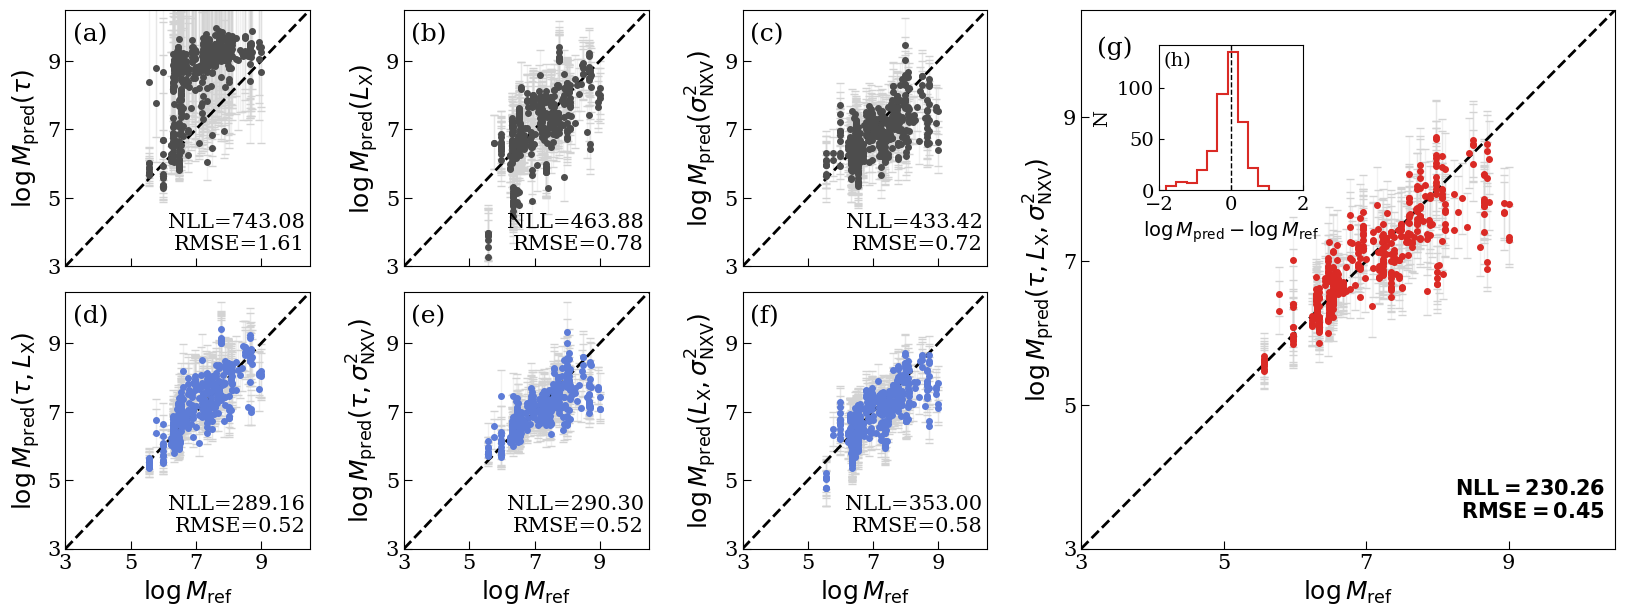

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

order = [
    ("LOGMBH_0", "LOGMBH_0_ERR_LO", "LOGMBH_0_ERR_HI", r"$\log M_{\rm pred}(\tau)$"),
    ("LOGMBH_1", "LOGMBH_1_ERR_LO", "LOGMBH_1_ERR_HI", r"$\log M_{\rm pred}(L_{\rm X})$"),
    ("LOGMBH_2", "LOGMBH_2_ERR_LO", "LOGMBH_2_ERR_HI", r"$\log M_{\rm pred}(\sigma^2_{\rm NXV})$"),
    ("LOGMBH_3", "LOGMBH_3_ERR_LO", "LOGMBH_3_ERR_HI", r"$\log M_{\rm pred}(\tau, L_{\rm X})$"),
    ("LOGMBH_4", "LOGMBH_4_ERR_LO", "LOGMBH_4_ERR_HI", r"$\log M_{\rm pred}(\tau, \sigma^2_{\rm NXV})$"),
    ("LOGMBH_5", "LOGMBH_5_ERR_LO", "LOGMBH_5_ERR_HI", r"$\log M_{\rm pred}(L_{\rm X}, \sigma^2_{\rm NXV})$"),
    ("LOGMBH_6", "LOGMBH_6_ERR_LO", "LOGMBH_6_ERR_HI", r"$\log M_{\rm pred}(\tau, L_{\rm X}, \sigma^2_{\rm NXV})$")
]

colors = ["#4D4D4D"]*3 + ["#5D7CD7"]*3 + ["#DA2A25"]
panel_labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)", "(g)"]

fig = plt.figure(figsize=(20, 7))
gs = gridspec.GridSpec(2, 5, figure=fig, wspace=0.4, hspace=0.1, 
                       width_ratios=[1,1,1,1,0.8])

axes = [
    fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[0, 2]),
    fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1]), fig.add_subplot(gs[1, 2]),
    fig.add_subplot(gs[:, 3:])
]

for i, ax in enumerate(axes):
    ycol, lo, hi, ylabel = order[i]
    color = colors[i]

    y_pred = dfx[ycol].values
    y_err = 0.5 * (dfx[lo].values + dfx[hi].values)
    y_ref = dfx["LOGMBH"].values
    y_ref_err = dfx["LOGMBH_ERR"].values

    ax.errorbar(
        y_ref, y_pred,
        yerr=[dfx[lo], dfx[hi]],
        fmt="o",
        markersize=4,
        color=color,                
        ecolor="lightgray",         
        elinewidth=1,               
        capsize=3,                  
        capthick=1,                 
    )

    ax.plot([3, 10.5], [3, 10.5], "k--", linewidth=2)
    ax.set_xlim(3, 10.5)
    ax.set_ylim(3, 10.5)
    ax.set_xticks(np.arange(3, 11, 2))
    ax.set_yticks(np.arange(3, 11, 2))
    ax.tick_params(axis='both', which='major', labelsize=15, length=6)

    if i >= 3:
        ax.set_xlabel(r"$\log M_{\rm ref}$", fontsize=18)
    else:
        ax.set_xticklabels([])

    ax.set_ylabel(ylabel, fontsize=18)

    var_total = y_err**2 + y_ref_err**2
    nll = 0.5 * np.sum((y_ref - y_pred)**2 / var_total  + np.log(2 * np.pi * var_total) )

    
    rmse = np.sqrt(np.mean((y_ref - y_pred)**2))

    ax.text(0.03, 0.95, panel_labels[i], fontsize=18,
            ha='left', va='top', transform=ax.transAxes)
    if i<6:
        ax.text(0.98, 0.05, f"NLL={nll:.2f}\nRMSE={rmse:.2f}",
            fontsize=15, color='black', ha='right', va='bottom', transform=ax.transAxes)
    else:
        ax.text(0.98, 0.05, fr"$\bf NLL={nll:.2f}$"+"\n"+fr"$\bf RMSE={rmse:.2f}$",
            fontsize=15,color='black', ha='right', va='bottom', transform=ax.transAxes)
    for c in ax.collections:
        c.set_alpha(0.3)

ax_main = axes[-1]
ax_inset = inset_axes(ax_main, width="30%", height="30%", loc='upper left', 
                      bbox_to_anchor=(0.13, 0.05, 0.9, 0.9), bbox_transform=ax_main.transAxes)
ax_inset.axvline(0, color='k', ls='--',lw=1)
ax_inset.text(0.03, 0.95, "(h)", fontsize=14,
            ha='left', va='top', transform=ax_inset.transAxes)             
ax_inset.hist(y_pred - y_ref, bins=10, color="#DA2A25", histtype='step',lw=1.5)
ax_inset.set_xlabel(r"$\log M_{\rm pred} - \log M_{\rm ref}$", fontsize=14)
ax_inset.set_ylabel(r"N", fontsize=14)
ax_inset.tick_params(axis='both', labelsize=14)
ax_inset.set_xlim(-2,2)
fig.savefig(paper_dir / "fig3.png", bbox_inches='tight')

## Source-wise (Appendix A)

In [22]:
def estimate_one_source(task):
    src_name, rows = task
    result = {}

    for j in range(7):
        estimator = MassEstimator()

        mass_col = f"LOGMBH_{j}"
        err_lo_col = f"LOGMBH_{j}_ERR_LO"
        err_hi_col = f"LOGMBH_{j}_ERR_HI"

        for par in rows:
            mass_err = 0.5 * (
                par[err_lo_col] + par[err_hi_col]
            )

            estimator.add_Mest(
                par[mass_col],
                mass_err,
            )

        samples = estimator.estimate(
            pool_size=1,
            progress=False,
        )

        q16, median, q84 = np.percentile(
            samples,
            [16, 50, 84],
        )

        result[f"LOGMBH_{j}s"] = median
        result[f"LOGMBH_{j}s_ERR_HI"] = q84 - median
        result[f"LOGMBH_{j}s_ERR_LO"] = median - q16

    return src_name, result

In [23]:

# required_columns = []

# for j in range(7):
#     required_columns.extend([
#         f"LOGMBH_{j}",
#         f"LOGMBH_{j}_ERR_LO",
#         f"LOGMBH_{j}_ERR_HI",
#     ])

# tasks = [
#     (
#         src_name,
#         group[required_columns].to_dict("records"),
#     )
#     for src_name, group in dfx.groupby("src_name")
# ]

# n_processes = min(12, len(tasks))

# with mp.Pool(processes=n_processes) as pool:
#     result_pairs = list(
#         tqdm(
#             pool.imap_unordered(
#                 estimate_one_source,
#                 tasks,
#                 chunksize=1,
#             ),
#             total=len(tasks),
#             desc="Combining observations by source",
#         )
#     )

# source_result_df = pandas.DataFrame.from_dict(
#     dict(result_pairs),
#     orient="index",
# )

# source_result_df.index.name = "src_name"

# for column in source_result_df.columns:
#     dfx[column] = dfx["src_name"].map(
#         source_result_df[column]
#     )

# dfx.to_pickle(dfx_path)

In [24]:
dfx = pandas.read_pickle(dfx_path)

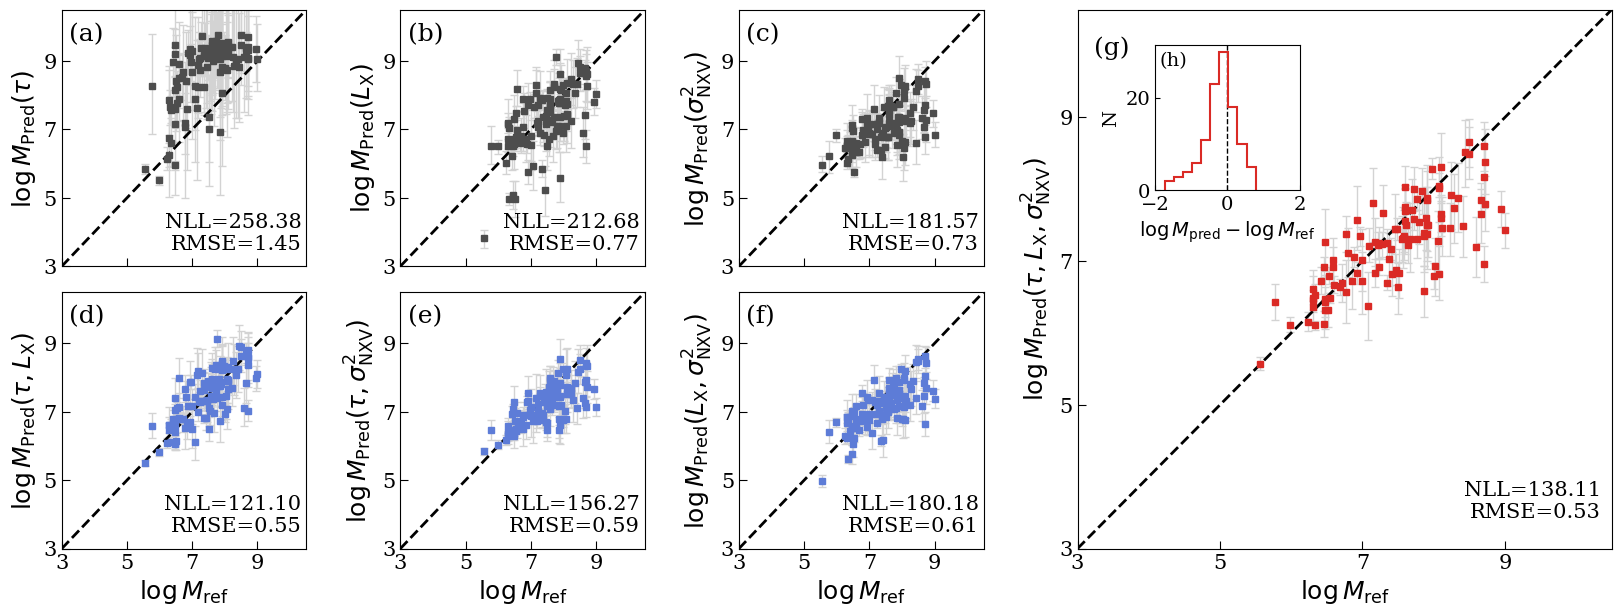

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

order = [
    ("LOGMBH_0s", "LOGMBH_0s_ERR_LO", "LOGMBH_0s_ERR_HI", r"$\log M_{\rm Pred}(\tau)$"),
    ("LOGMBH_1s", "LOGMBH_1s_ERR_LO", "LOGMBH_1s_ERR_HI", r"$\log M_{\rm Pred}(L_{\rm X})$"),
    ("LOGMBH_2s", "LOGMBH_2s_ERR_LO", "LOGMBH_2s_ERR_HI", r"$\log M_{\rm Pred}(\sigma^2_{\rm NXV})$"),
    ("LOGMBH_3s", "LOGMBH_3s_ERR_LO", "LOGMBH_3s_ERR_HI", r"$\log M_{\rm Pred}(\tau, L_{\rm X})$"),
    ("LOGMBH_4s", "LOGMBH_4s_ERR_LO", "LOGMBH_4s_ERR_HI", r"$\log M_{\rm Pred}(\tau, \sigma^2_{\rm NXV})$"),
    ("LOGMBH_5s", "LOGMBH_5s_ERR_LO", "LOGMBH_5s_ERR_HI", r"$\log M_{\rm Pred}(L_{\rm X}, \sigma^2_{\rm NXV})$"),
    ("LOGMBH_6s", "LOGMBH_6s_ERR_LO", "LOGMBH_6s_ERR_HI", r"$\log M_{\rm Pred}(\tau, L_{\rm X}, \sigma^2_{\rm NXV})$")
]

colors = ["#4D4D4D"]*3 + ["#5D7CD7"]*3 + ["#DA2A25"]
panel_labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)", "(g)"]

fig = plt.figure(figsize=(20, 7))
gs = gridspec.GridSpec(2, 5, figure=fig, wspace=0.4, hspace=0.1, 
                       width_ratios=[1,1,1,1,0.8])

axes = [
    fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[0, 2]),
    fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1]), fig.add_subplot(gs[1, 2]),
    fig.add_subplot(gs[:, 3:])
]

source_group = dfx.groupby("src_name").first()

for i, ax in enumerate(axes):
    ycol, lo, hi, ylabel = order[i]
    color = colors[i]

    y_pred = source_group[ycol].values
    y_err = 0.5 * (source_group[lo].values + source_group[hi].values)
    y_ref = source_group["LOGMBH"].values
    y_ref_err = source_group["LOGMBH_ERR"].values
    
    ax.errorbar(
        y_ref, y_pred,
        yerr=[source_group[lo], source_group[hi]],
        fmt="s",
        markersize=4,
        color=color,                
        ecolor="lightgray",         
        elinewidth=1,               
        capsize=3,                  
        capthick=1,                 
    )
    ax.plot([3, 10.5], [3, 10.5], "k--", linewidth=2)
    ax.set_xlim(3, 10.5)
    ax.set_ylim(3, 10.5)
    ax.set_xticks(np.arange(3, 11, 2))
    ax.set_yticks(np.arange(3, 11, 2))
    ax.tick_params(axis='both', which='major', labelsize=15, length=6)

    if i >= 3:
        ax.set_xlabel(r"$\log M_{\rm ref}$", fontsize=18)
    else:
        ax.set_xticklabels([])

    ax.set_ylabel(ylabel, fontsize=18)

    var_total = y_err**2 + y_ref_err**2
    nll = 0.5 * np.sum((y_ref - y_pred)**2 / var_total  + np.log(2 * np.pi * var_total) )

    rmse = np.sqrt(np.mean((y_ref - y_pred)**2))

    ax.text(0.03, 0.95, panel_labels[i], fontsize=18,
            ha='left', va='top', transform=ax.transAxes)

    ax.text(0.98, 0.05, f"NLL={nll:.2f}\nRMSE={rmse:.2f}",
            fontsize=15, color='black', ha='right', va='bottom', transform=ax.transAxes)

ax_main = axes[-1]
ax_inset = inset_axes(ax_main, width="30%", height="30%", loc='upper left', 
                      bbox_to_anchor=(0.13, 0.05, 0.9, 0.9), bbox_transform=ax_main.transAxes)
ax_inset.axvline(0, color='k', ls='--',lw=1)
ax_inset.text(0.03, 0.95, "(h)", fontsize=14,
            ha='left', va='top', transform=ax_inset.transAxes)             
ax_inset.hist(y_pred - y_ref, bins=10, color="#DA2A25", histtype='step',lw=1.5)
ax_inset.set_xlabel(r"$\log M_{\rm pred} - \log M_{\rm ref}$", fontsize=14)
ax_inset.set_ylabel(r"N", fontsize=14)
ax_inset.tick_params(axis='both', labelsize=14)
ax_inset.set_xlim(-2,2)
fig.savefig(paper_dir / "figA.png", bbox_inches='tight')